# Checking AI Responses


This notebook was created to check if the responses AI gave me were correct based on the World_Bank_CO2_Cleaned.tsv file. Each AI code runs the World_Bank_CO2_RawData.tsv file. This notebook includes runs from part 2 and part 3.


# Part 2

## My code:

{'Country Name': 'Angola', 'Country Code': 'AGO', 'Region': 'Sub-Saharan Africa', 'Year': '2004', 'CO2 (kt)': '18,793.38'}
11127


,CO2 Emissions (kt),Percentage (%)
Region,,
Sub-Saharan Africa,713656.88,2.28
Latin America & Caribbean,1691634.80,5.40
South Asia,2197647.77,7.01
Middle East & North Africa,2304753.51,7.36
North America,5905450.47,18.85
Europe & Central Asia,6761346.65,21.58
East Asia & Pacific,11757194.06,37.52


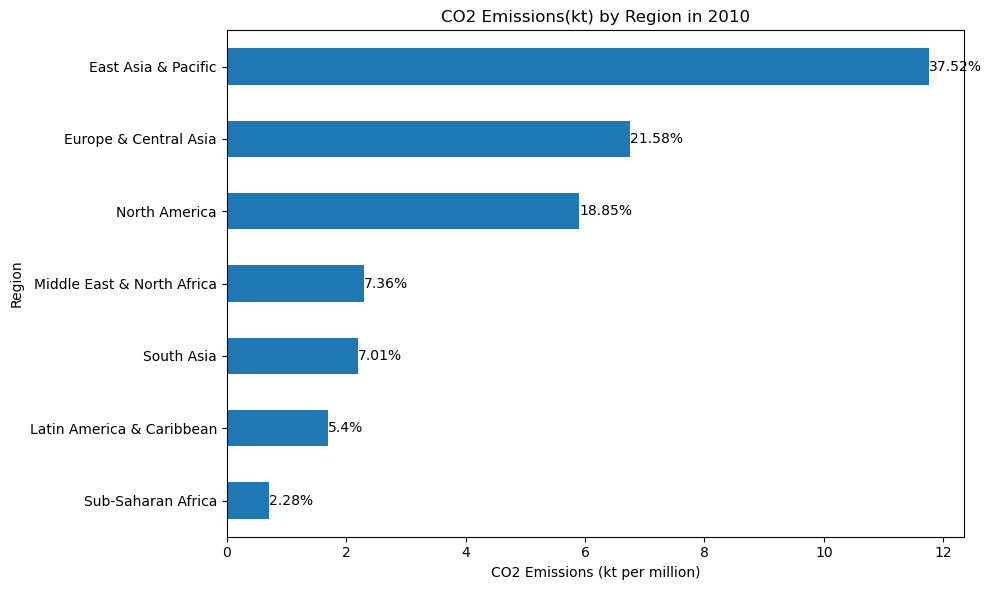

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import csv
import requests
from IPython.display import display
import math



def prepare_datasets(file_path):
    #From A2
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts


co2_emissions = prepare_datasets("My Datasets/World_Bank_CO2_Cleaned.tsv")
print(co_emissions[200])
print(len(co_emissions))


df = pd.DataFrame(co2_emissions)
df.head()

df_2010 = df[df["Year"] == "2010"].copy()

df_2010["CO2 (kt)"] = pd.to_numeric(
    df_2010["CO2 (kt)"].str.replace(",", ""),
    errors="coerce"
)


#Rewritten and changed from A2
by_region = df_2010.groupby("Region")["CO2 (kt)"].sum()

co2_percentage = (by_region / by_region.sum() * 100).round(2)

co2_data = {
    "CO2 Emissions (kt)": by_region,
    "Percentage (%)": co2_percentage
}


co2_unsorted = pd.DataFrame(data=co2_data)

co2_table = co2_unsorted.sort_values(
    by="CO2 Emissions (kt)",
    ascending=True
)

co2_table["CO2 Emissions (kt)"] = co2_table["CO2 Emissions (kt)"].round(2)

display(co2_table)

# Create bar chart

ax = (co2_table["CO2 Emissions (kt)"]/ 1000000).plot.barh(
    figsize=(10, 6),
    xlabel="CO2 Emissions (kt per million)",
    ylabel="Region",
    legend=False
)
ax.ticklabel_format(axis="x", style="plain")

for i, percentage in enumerate(co2_table["Percentage (%)"]):
    ax.text(
        (co2_table["CO2 Emissions (kt)"]/ 1000000).iloc[i],
        i,
        f"{percentage}%",
        va="center",
        ha="left"
    )

plt.title("CO2 Emissions(kt) by Region in 2010")
plt.tight_layout()
plt.show()





## AI Run 1 - ChatGPT (Version Unknown)

                            Country Name Country Code
Fragile and conflict affected situations          FCS
                                  Kosovo          KSV
                    High income: nonOECD          NOC
                       High income: OECD          OEC

CO2 Emissions by World Bank Geographic Region (2010)
                                           Region  CO2 Emissions (kt)  Percentage (%)
                                       Aggregates        164995623.47           84.04
                              East Asia & Pacific         11757194.07            5.99
                            Europe & Central Asia          6761346.61            3.44
                                    North America          5905450.48            3.01
Middle East, North Africa, Afghanistan & Pakistan          2476017.07            1.26
                                       South Asia          2026384.20            1.03
                       Latin America & Caribbean           1691634.77     

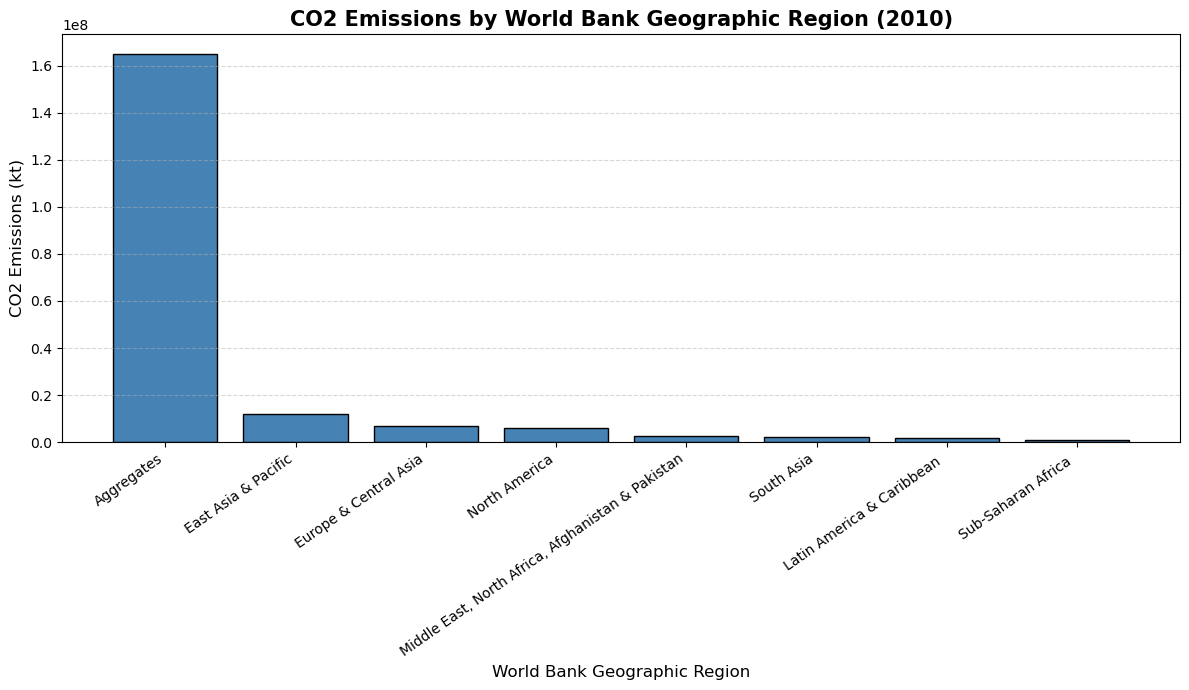


Results saved successfully!


<Figure size 640x480 with 0 Axes>

In [54]:

import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LOAD THE DATASET
# --------------------------------------------------

file_name = "My Datasets/World_Bank_CO2_RawData.tsv"

df = pd.read_csv(file_name, sep="\t")

# Clean column names and country codes
df.columns = df.columns.str.strip()
df["Country Code"] = df["Country Code"].astype(str).str.strip().str.upper()

# --------------------------------------------------
# 2. GET WORLD BANK COUNTRY-TO-REGION CLASSIFICATIONS
# --------------------------------------------------

# Retrieve country metadata from the World Bank API
api_url = (
    "https://api.worldbank.org/v2/country"
    "?format=json&per_page=400"
)

wb_response = pd.read_json(api_url, typ="series")

# The second element contains the country records
wb_countries = pd.json_normalize(wb_response.iloc[1])

# Keep the country code and geographic region
region_data = wb_countries[
    ["id", "region.value"]
].copy()

region_data.columns = ["Country Code", "Region"]

# Remove aggregate entries that do not have a geographic region
region_data = region_data.dropna(subset=["Region"])

# Remove empty region values
region_data = region_data[
    region_data["Region"].str.strip() != ""
]

# Create a dictionary matching country codes to regions
country_region = dict(
    zip(region_data["Country Code"], region_data["Region"])
)

# --------------------------------------------------
# 3. CREATE THE REGION COLUMN
# --------------------------------------------------

df["Region"] = df["Country Code"].map(country_region)

# Check for countries that could not be matched
unmatched = df.loc[
    df["Region"].isna(),
    ["Country Name", "Country Code"]
].drop_duplicates()

if not unmatched.empty:
    print("WARNING: The following entries have no region match:")
    print(unmatched.to_string(index=False))

# --------------------------------------------------
# 4. SELECT CO2 EMISSIONS FOR 2010
# --------------------------------------------------

# Convert 2010 emissions to numeric values
df["2010"] = pd.to_numeric(df["2010"], errors="coerce")

# Keep only entries with a geographic region
# and valid CO2 emissions data
df_2010 = df[
    (df["Region"].notna()) &
    (df["2010"].notna())
].copy()

# --------------------------------------------------
# 5. GROUP COUNTRIES BY REGION
# --------------------------------------------------

# Sum CO2 emissions (kt) for each geographic region
region_emissions = (
    df_2010.groupby("Region")["2010"]
    .sum()
    .reset_index()
)

# Rename columns for clarity
region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

# --------------------------------------------------
# 6. CALCULATE PERCENTAGES
# --------------------------------------------------

# Calculate total emissions across the included regions
total_emissions = region_emissions["CO2 Emissions (kt)"].sum()

# Calculate each region's percentage of total emissions
region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"]
    / total_emissions
) * 100

# Sort regions from highest to lowest emissions
region_emissions = region_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
)

# Round values for presentation
region_emissions["CO2 Emissions (kt)"] = (
    region_emissions["CO2 Emissions (kt)"].round(2)
)

region_emissions["Percentage (%)"] = (
    region_emissions["Percentage (%)"].round(2)
)

# --------------------------------------------------
# 7. DISPLAY THE RESULTS TABLE
# --------------------------------------------------

print("\nCO2 Emissions by World Bank Geographic Region (2010)")
print("=" * 65)

print(region_emissions.to_string(index=False))

print("\nTotal CO2 Emissions (kt):",
      f"{total_emissions:,.2f}")

# --------------------------------------------------
# 8. CREATE A BAR CHART
# --------------------------------------------------

plt.figure(figsize=(12, 7))

plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

# Chart title and axis labels
plt.title(
    "CO2 Emissions by World Bank Geographic Region (2010)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("World Bank Geographic Region", fontsize=12)

plt.ylabel("CO2 Emissions (kt)", fontsize=12)

# Rotate region labels for readability
plt.xticks(rotation=35, ha="right")

# Add gridlines
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

# --------------------------------------------------
# 9. OPTIONAL: SAVE RESULTS
# --------------------------------------------------

region_emissions.to_csv(
    "CO2_Emissions_by_Region_2010.csv",
    index=False
)

plt.savefig(
    "CO2_Emissions_by_Region_2010.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nResults saved successfully!")


## AI Run 2 - ChatGPT

In [56]:

# ============================================================
# CO2 EMISSIONS BY WORLD BANK REGION (2010)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD THE DATASET
# ------------------------------------------------------------

file_name = "My Datasets/World_Bank_CO2_RawData.tsv"

df = pd.read_csv(file_name, sep="\t")

# Display column names to check the dataset
print("Dataset columns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. RETRIEVE WORLD BANK COUNTRY-TO-REGION CLASSIFICATIONS
# ------------------------------------------------------------

# World Bank API: country metadata
# Includes country codes, names and geographic regions.

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

wb_data = pd.read_json(url)

# The second element contains the country records
countries = pd.json_normalize(wb_data.iloc[1])

# Keep only the relevant columns
region_data = countries[["id", "name", "region.value"]].copy()

# Rename columns to match the main dataset
region_data.columns = ["Country Code", "WB Country Name", "Region"]

# Remove regional/income aggregates rather than countries
region_data = region_data[
    region_data["Region"] != "Aggregates"
]

# Remove empty region classifications
region_data = region_data[
    region_data["Region"].notna()
    & (region_data["Region"] != "")
]

# Remove any duplicate country codes
region_data = region_data.drop_duplicates(
    subset="Country Code"
)


# ------------------------------------------------------------
# 3. CREATE THE REGION COLUMN
# ------------------------------------------------------------

# Match countries using their Country Code
df = df.merge(
    region_data[["Country Code", "Region"]],
    on="Country Code",
    how="left"
)

# Check countries that could not be assigned a region
unmatched = df.loc[
    df["Region"].isna(),
    ["Country Name", "Country Code"]
].drop_duplicates()

if not unmatched.empty:
    print("\nCountries without a matched region:")
    print(unmatched.to_string(index=False))


# ------------------------------------------------------------
# 4. FILTER DATA FOR THE YEAR 2010
# ------------------------------------------------------------

# The World Bank raw data commonly uses years as columns.
# Select the 2010 column.

year = "2010"

if year not in df.columns:
    raise KeyError(
        f"Column '{year}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert emissions data to numeric values
df[year] = pd.to_numeric(df[year], errors="coerce")

# Keep only countries with a region and valid 2010 data
df_2010 = df[
    df["Region"].notna()
    & df[year].notna()
].copy()


# ------------------------------------------------------------
# 5. CALCULATE TOTAL CO2 EMISSIONS BY REGION
# ------------------------------------------------------------

# Group countries by their geographic region
regional_emissions = (
    df_2010
    .groupby("Region")[year]
    .sum()
    .reset_index()
)

# Rename the emissions column
regional_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

# Calculate total emissions across the represented regions
total_emissions = regional_emissions[
    "CO2 Emissions (kt)"
].sum()

# Calculate each region's percentage contribution
regional_emissions["Percentage (%)"] = (
    regional_emissions["CO2 Emissions (kt)"]
    / total_emissions
) * 100

# Sort regions from highest to lowest emissions
regional_emissions = regional_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
)

# Format the table for presentation
regional_emissions["CO2 Emissions (kt)"] = (
    regional_emissions["CO2 Emissions (kt)"].round(2)
)

regional_emissions["Percentage (%)"] = (
    regional_emissions["Percentage (%)"].round(2)
)


# ------------------------------------------------------------
# 6. DISPLAY THE RESULTS TABLE
# ------------------------------------------------------------

print("\n==============================================")
print("WORLD BANK REGIONAL CO2 EMISSIONS - 2010")
print("==============================================")

print(regional_emissions.to_string(index=False))

print("\nTotal CO2 emissions (kt):",
      round(total_emissions, 2))


# ------------------------------------------------------------
# 7. CREATE A BAR CHART
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

bars = plt.bar(
    regional_emissions["Region"],
    regional_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

# Add title and axis labels
plt.title(
    "CO2 Emissions by World Bank Geographic Region (2010)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("World Bank Geographic Region", fontsize=12)

plt.ylabel("CO2 Emissions (kt)", fontsize=12)

# Rotate region names for readability
plt.xticks(rotation=35, ha="right")

# Add emissions values above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Display the chart
plt.show()


# ------------------------------------------------------------
# 8. OPTIONAL: SAVE RESULTS
# ------------------------------------------------------------

regional_emissions.to_csv(
    "CO2_Emissions_By_Region_2010.csv",
    index=False
)

plt.savefig(
    "CO2_Emissions_By_Region_2010.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nResults saved successfully!")


Dataset columns:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015']


AttributeError: 'list' object has no attribute 'keys'

## AI Run 3 - ChatGPT


WORLD BANK CO2 EMISSIONS BY REGION (2010)
                                           Region  CO2 Emissions (kt)  Percentage (%)
                                       Aggregates        164995623.47           84.04
                              East Asia & Pacific         11757194.07            5.99
                            Europe & Central Asia          6761346.61            3.44
                                    North America          5905450.48            3.01
Middle East, North Africa, Afghanistan & Pakistan          2476017.07            1.26
                                       South Asia          2026384.20            1.03
                       Latin America & Caribbean           1691634.77            0.86
                              Sub-Saharan Africa            713656.87            0.36

Total CO2 Emissions (kt): 196,327,307.55


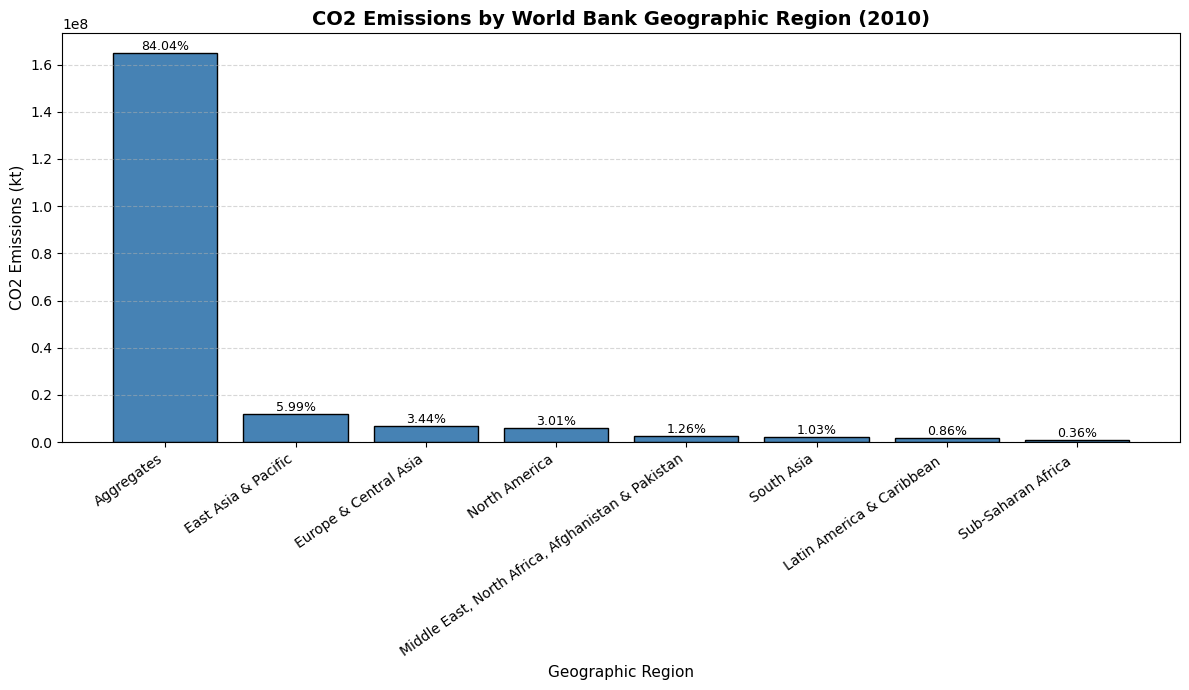

In [57]:

import pandas as pd
import matplotlib.pyplot as plt
import json
from urllib.request import urlopen

# ============================================================
# STEP 1: LOAD THE DATASET
# ============================================================

file_name = "My Datasets/World_Bank_CO2_RawData.tsv"

df = pd.read_csv(file_name, sep="\t")

# Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()

# ============================================================
# STEP 2: RETRIEVE WORLD BANK COUNTRY-REGION CLASSIFICATIONS
# ============================================================

# World Bank API: retrieves country codes and geographic regions
url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

with urlopen(url) as response:
    world_bank_data = json.loads(response.read().decode("utf-8"))

countries = world_bank_data[1]

# Create a dictionary mapping country codes to geographic regions
country_region = {}

for country in countries:

    country_code = country["id"]
    region = country["region"]["value"]

    # Exclude regional aggregates and other non-country entries
    if country["region"]["id"] != "":
        country_region[country_code] = region

# Create a new Region column using Country Code
df["Country Code"] = df["Country Code"].astype(str).str.strip().str.upper()

df["Region"] = df["Country Code"].map(country_region)

# ============================================================
# STEP 3: SELECT CO2 EMISSIONS FOR 2010
# ============================================================

# Identify the 2010 column
year_column = "2010"

# If the dataset contains multiple indicators, select CO2 emissions
if "Series Code" in df.columns:
    df = df[df["Series Code"] == "EN.ATM.CO2E.KT"]

elif "Indicator Code" in df.columns:
    df = df[df["Indicator Code"] == "EN.ATM.CO2E.KT"]

# Convert 2010 emissions to numeric values
df[year_column] = pd.to_numeric(df[year_column], errors="coerce")

# Remove rows without a valid region or emissions value
df = df.dropna(subset=["Region", year_column])

# ============================================================
# STEP 4: GROUP COUNTRIES BY REGION
# ============================================================

# Sum the CO2 emissions of all countries within each region
region_emissions = (
    df.groupby("Region")[year_column]
    .sum()
    .reset_index()
)

# Rename columns for clarity
region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

# ============================================================
# STEP 5: CALCULATE PERCENTAGE CONTRIBUTIONS
# ============================================================

# Calculate the total emissions across all included regions
total_emissions = region_emissions["CO2 Emissions (kt)"].sum()

# Calculate each region's percentage contribution
region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"]
    / total_emissions
    * 100
)

# Sort regions from highest to lowest emissions
region_emissions = region_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
)

# Format the results for presentation
region_emissions["CO2 Emissions (kt)"] = (
    region_emissions["CO2 Emissions (kt)"].round(2)
)

region_emissions["Percentage (%)"] = (
    region_emissions["Percentage (%)"].round(2)
)

# ============================================================
# STEP 6: DISPLAY THE RESULTS TABLE
# ============================================================

print("\nWORLD BANK CO2 EMISSIONS BY REGION (2010)")
print("=" * 65)

print(region_emissions.to_string(index=False))

print("\nTotal CO2 Emissions (kt):",
      f"{total_emissions:,.2f}")

# ============================================================
# STEP 7: CREATE A BAR CHART
# ============================================================

plt.figure(figsize=(12, 7))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

# Add percentage labels above each bar
for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{percentage:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Chart title and axis labels
plt.title(
    "CO2 Emissions by World Bank Geographic Region (2010)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Geographic Region", fontsize=11)

plt.ylabel("CO2 Emissions (kt)", fontsize=11)

plt.xticks(rotation=35, ha="right")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Display the chart
plt.show()


## AI Run 4 - Claude (Sonnet 5.5)

Excluded (aggregates / unmapped): ['Arab World', 'Central Europe and the Baltics', 'Caribbean small states', 'East Asia & Pacific (developing only)', 'East Asia & Pacific (all income levels)', 'Europe & Central Asia (developing only)', 'Europe & Central Asia (all income levels)', 'Euro area', 'European Union', 'Fragile and conflict affected situations', 'High income', 'Heavily indebted poor countries (HIPC)', 'Not classified', 'Kosovo', 'Latin America & Caribbean (developing only)', 'Latin America & Caribbean (all income levels)', 'Least developed countries: UN classification', 'Low income', 'Lower middle income', 'Low & middle income', 'Middle East & North Africa (all income levels)', 'Middle income', 'Middle East & North Africa (developing only)', 'North America', 'High income: nonOECD', 'High income: OECD', 'OECD members', 'Other small states', 'Pacific island small states', 'South Asia', 'Sub-Saharan Africa (developing only)', 'Sub-Saharan Africa (all income levels)', 'Small states

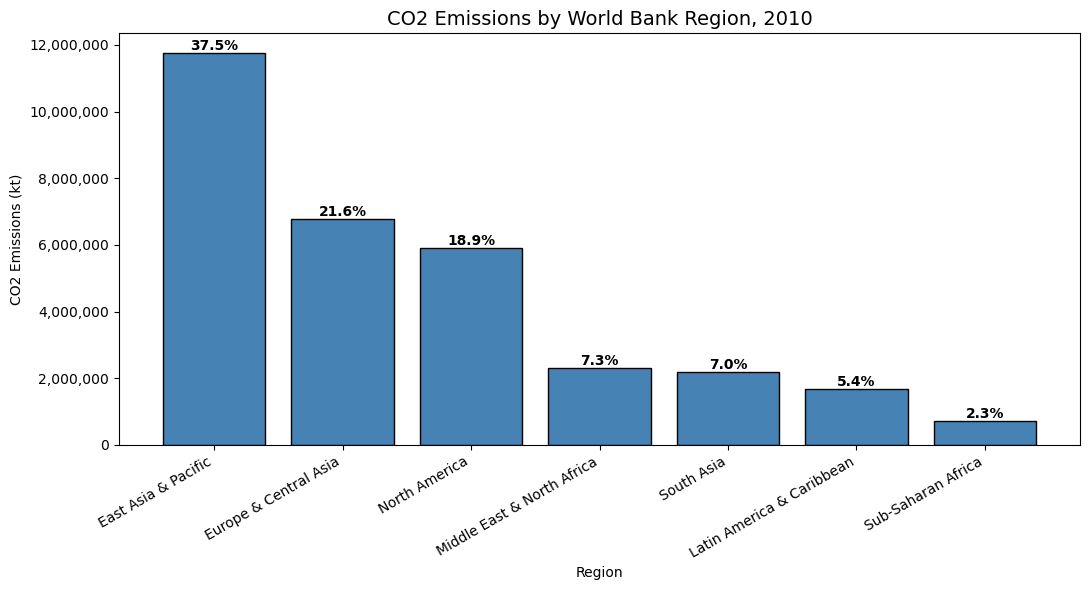

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# 1. Load the data
# ------------------------------------------------------------------
df = pd.read_csv("World_Bank_CO2_RawData.tsv", sep="\t")
df.columns = df.columns.str.strip()

# Find the 2010 column (handles "2010" or "2010 [YR2010]")
year_col = next(c for c in df.columns if c.startswith("2010"))

# World Bank files use ".." for missing values -> convert to NaN
df[year_col] = pd.to_numeric(df[year_col], errors="coerce")

# ------------------------------------------------------------------
# 2. World Bank region assignment (by ISO3 Country Code)
# ------------------------------------------------------------------
region_codes = {
    "East Asia & Pacific": [
        "ASM", "AUS", "BRN", "KHM", "CHN", "FJI", "PYF", "GUM", "HKG", "IDN",
        "JPN", "KIR", "PRK", "KOR", "LAO", "MAC", "MYS", "MHL", "FSM", "MNG",
        "MMR", "NRU", "NCL", "NZL", "MNP", "PLW", "PNG", "PHL", "WSM", "SGP",
        "SLB", "THA", "TLS", "TON", "TUV", "VUT", "VNM",
    ],
    "Europe & Central Asia": [
        "ALB", "AND", "ARM", "AUT", "AZE", "BLR", "BEL", "BIH", "BGR", "CHI",
        "HRV", "CYP", "CZE", "DNK", "EST", "FRO", "FIN", "FRA", "GEO", "DEU",
        "GIB", "GRC", "GRL", "HUN", "ISL", "IRL", "IMN", "ITA", "KAZ", "XKX",
        "KGZ", "LVA", "LIE", "LTU", "LUX", "MLT", "MDA", "MCO", "MNE", "NLD",
        "MKD", "NOR", "POL", "PRT", "ROU", "RUS", "SMR", "SRB", "SVK", "SVN",
        "ESP", "SWE", "CHE", "TJK", "TUR", "TKM", "UKR", "GBR", "UZB",
    ],
    "Latin America & Caribbean": [
        "ATG", "ARG", "ABW", "BHS", "BRB", "BLZ", "BOL", "BRA", "VGB", "CYM",
        "CHL", "COL", "CRI", "CUB", "CUW", "DMA", "DOM", "ECU", "SLV", "GRD",
        "GTM", "GUY", "HTI", "HND", "JAM", "MEX", "NIC", "PAN", "PRY", "PER",
        "PRI", "SXM", "KNA", "LCA", "MAF", "VCT", "SUR", "TTO", "TCA", "URY",
        "VEN", "VIR",
    ],
    "Middle East & North Africa": [
        "DZA", "BHR", "DJI", "EGY", "IRN", "IRQ", "ISR", "JOR", "KWT", "LBN",
        "LBY", "MAR", "OMN", "QAT", "SAU", "SYR", "TUN", "ARE", "PSE", "YEM",
    ],
    "North America": ["BMU", "CAN", "USA"],
    "South Asia": ["AFG", "BGD", "BTN", "IND", "MDV", "NPL", "PAK", "LKA"],
    "Sub-Saharan Africa": [
        "AGO", "BEN", "BWA", "BFA", "BDI", "CPV", "CMR", "CAF", "TCD", "COM",
        "COD", "COG", "CIV", "GNQ", "ERI", "SWZ", "ETH", "GAB", "GMB", "GHA",
        "GIN", "GNB", "KEN", "LSO", "LBR", "MDG", "MWI", "MLI", "MRT", "MUS",
        "MOZ", "NAM", "NER", "NGA", "RWA", "STP", "SEN", "SYC", "SLE", "SOM",
        "ZAF", "SSD", "SDN", "TZA", "TGO", "UGA", "ZMB", "ZWE",
    ],
}

# Invert to {country_code: region}
code_to_region = {code: region
                  for region, codes in region_codes.items()
                  for code in codes}

# Create the Region column
df["Region"] = df["Country Code"].str.strip().map(code_to_region)

# Rows with no region are aggregates (World, High income, etc.) or unmapped.
# Drop them so they don't double count.
unmapped = df[df["Region"].isna()]["Country Name"].dropna().unique()
print("Excluded (aggregates / unmapped):", list(unmapped), "\n")
df = df.dropna(subset=["Region"])

# ------------------------------------------------------------------
# 3. CO2 emissions by region in 2010
# ------------------------------------------------------------------
region_totals = (
    df.groupby("Region")[year_col]
      .sum(min_count=1)          # NaN-only groups stay NaN instead of 0
      .sort_values(ascending=False)
      .reset_index()
)
region_totals.columns = ["Region", "CO2 Emissions 2010 (kt)"]

total = region_totals["CO2 Emissions 2010 (kt)"].sum()
region_totals["Percentage of Total (%)"] = (
    region_totals["CO2 Emissions 2010 (kt)"] / total * 100
).round(2)

print("CO2 Emissions by Region, 2010")
print(region_totals.to_string(index=False, formatters={
    "CO2 Emissions 2010 (kt)": "{:,.0f}".format,
    "Percentage of Total (%)": "{:.2f}%".format,
}))
print(f"\nTotal: {total:,.0f} kt")

# ------------------------------------------------------------------
# 4. Bar chart
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(region_totals["Region"],
              region_totals["CO2 Emissions 2010 (kt)"],
              color="steelblue", edgecolor="black")

# Label each bar with its percentage
for bar, pct in zip(bars, region_totals["Percentage of Total (%)"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{pct:.1f}%",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("CO2 Emissions by World Bank Region, 2010", fontsize=14)
ax.set_xlabel("Region")
ax.set_ylabel("CO2 Emissions (kt)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("co2_by_region_2010.png", dpi=300)
plt.show()

# Part 3 



I tested with one participant who used ChatGPT (Unknown version)

## Run 1


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from urllib.request import urlopen

# --------------------------------------------------
# 1. LOAD THE DATASET
# --------------------------------------------------

file_name = "World_Bank_CO2_RawData.tsv"

df = pd.read_csv(file_name, sep="\t")

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

# --------------------------------------------------
# 2. RETRIEVE WORLD BANK COUNTRY-REGION DATA
# --------------------------------------------------

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

with urlopen(url) as response:
    wb_data = json.loads(response.read().decode("utf-8"))

# The second element contains the country records
countries = wb_data[1]

# Create a dictionary mapping Country Code to Region
country_region = {}

for country in countries:

    country_code = country["id"]
    region = country["region"]["value"]

    # Exclude aggregates and other entries without
    # an assigned geographic region
    if country["region"]["id"] != "":
        country_region[country_code] = region

# Create the Region column using Country Code
df["Region"] = df["Country Code"].map(country_region)

# --------------------------------------------------
# 3. SELECT CO2 EMISSIONS FOR 2010
# --------------------------------------------------

# Find the column corresponding to 2010.
# This accommodates either "2010" or "2010 [YR2010]"
year_column = next(
    (col for col in df.columns if str(col).strip().startswith("2010")),
    None
)

if year_column is None:
    raise ValueError("Could not find a 2010 column in the dataset.")

# Convert emissions values to numeric.
# Non-numeric entries such as ".." become NaN.
df[year_column] = pd.to_numeric(
    df[year_column],
    errors="coerce"
)

# --------------------------------------------------
# 4. FILTER COUNTRY DATA
# --------------------------------------------------

# If the dataset contains multiple indicators,
# select only the CO2 emissions indicator.
if "Series Code" in df.columns:
    df = df[df["Series Code"] == "EN.ATM.CO2E.KT"].copy()

# Keep only countries with a valid geographic region
# and available CO2 emissions data
df_2010 = df.dropna(
    subset=["Region", year_column]
).copy()

# --------------------------------------------------
# 5. GROUP COUNTRIES BY REGION
# --------------------------------------------------

# Sum the CO2 emissions of all countries
# belonging to each World Bank region
region_emissions = (
    df_2010.groupby("Region")[year_column]
    .sum()
    .reset_index()
)

# Rename columns for clarity
region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

# --------------------------------------------------
# 6. CALCULATE PERCENTAGE CONTRIBUTIONS
# --------------------------------------------------

# Calculate total emissions across the regions
total_emissions = region_emissions["CO2 Emissions (kt)"].sum()

# Calculate each region's percentage contribution
region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"]
    / total_emissions
) * 100

# Sort regions from highest to lowest emissions
region_emissions = region_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
).reset_index(drop=True)

# Round values for presentation
region_emissions["CO2 Emissions (kt)"] = (
    region_emissions["CO2 Emissions (kt)"].round(2)
)

region_emissions["Percentage (%)"] = (
    region_emissions["Percentage (%)"].round(2)
)

# --------------------------------------------------
# 7. DISPLAY THE RESULTS TABLE
# --------------------------------------------------

print("\nCO2 Emissions by World Bank Region (2010)")
print("=" * 65)

print(region_emissions.to_string(index=False))

print("\nTotal CO2 Emissions:",
      round(total_emissions, 2), "kt")

# --------------------------------------------------
# 8. CREATE A BAR CHART
# --------------------------------------------------

plt.figure(figsize=(12, 7))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

# Add title and axis labels
plt.title(
    "CO2 Emissions by World Bank Region (2010)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("World Bank Region", fontsize=12)

plt.ylabel("CO2 Emissions (kt)", fontsize=12)

# Rotate region labels for readability
plt.xticks(rotation=35, ha="right")

# Add percentage labels above each bar
for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{percentage:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Improve layout
plt.tight_layout()

# Display chart
plt.show()

# --------------------------------------------------
# 9. OPTIONAL: SAVE RESULTS
# --------------------------------------------------

region_emissions.to_csv(
    "CO2_Emissions_by_Region_2010.csv",
    index=False
)

plt.figure(figsize=(12, 7))

plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

plt.title("CO2 Emissions by World Bank Region (2010)")
plt.xlabel("World Bank Region")
plt.ylabel("CO2 Emissions (kt)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "CO2_Emissions_by_Region_2010.png",
    dpi=300,
    bbox_inches="tight"
)

print("\nResults saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'World_Bank_CO2_RawData.tsv'

## Run 2


Dataset loaded successfully!
Dataset dimensions: (248, 60)
Available columns:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015']
Assuming the file already contains only CO2 emissions.

Using year column: 2010

World Bank country information retrieved!
Countries matched: 296

Countries without a matched region:
                            Country Name Country Code
Fragile and conflict affected situations          FCS
                                  Kosovo          KSV
                    High income: nonOECD          NOC
      

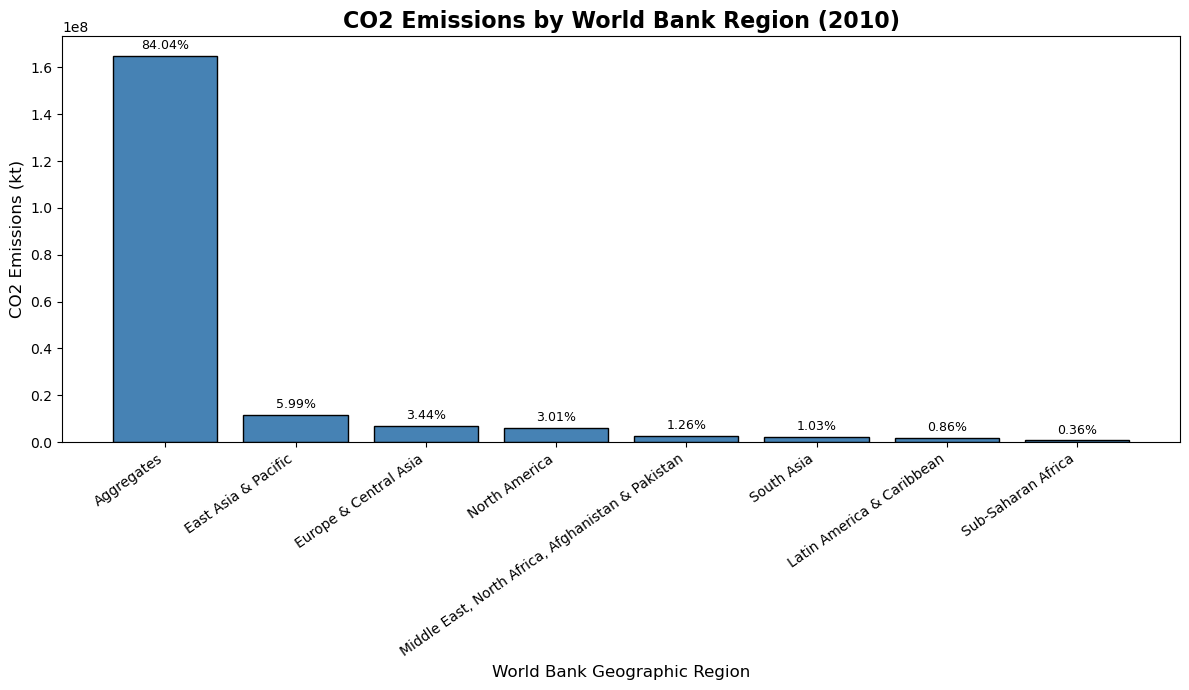


Results exported to:
CO2_Emissions_by_Region_2010.csv


In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from urllib.request import urlopen
from urllib.parse import urlencode

# ==================================================
# STEP 1: READ THE TSV FILE
# ==================================================

file_name = "My Datasets/World_Bank_CO2_RawData.tsv"

try:
    df = pd.read_csv(
        file_name,
        sep="\t",
        encoding="utf-8-sig"
    )

    # Clean column names
    df.columns = df.columns.astype(str).str.strip()

    print("Dataset loaded successfully!")
    print("Dataset dimensions:", df.shape)
    print("Available columns:")
    print(df.columns.tolist())

except FileNotFoundError:
    raise FileNotFoundError(
        "The file was not found. Make sure "
        "World_Bank_CO2_RawData.tsv is in your working directory."
    )


# ==================================================
# STEP 2: IDENTIFY THE CO2 INDICATOR
# ==================================================

# Filter for CO2 emissions (kt), if Series Code exists
if "Series Code" in df.columns:

    df["Series Code"] = df["Series Code"].astype(str).str.strip()

    df = df[
        df["Series Code"] == "EN.ATM.CO2E.KT"
    ].copy()

    if df.empty:
        raise ValueError(
            "No rows found for indicator EN.ATM.CO2E.KT. "
            "Check the Series Code column."
        )

elif "Series Name" in df.columns:

    df["Series Name"] = df["Series Name"].astype(str).str.strip()

    df = df[
        df["Series Name"].str.contains(
            "CO2 emissions",
            case=False,
            na=False
        )
    ].copy()

    if df.empty:
        raise ValueError("Could not identify the CO2 emissions indicator.")

else:
    print("Warning: No Series Code or Series Name column found.")
    print("Assuming the file already contains only CO2 emissions.")


# ==================================================
# STEP 3: IDENTIFY THE 2010 COLUMN
# ==================================================

year_columns = [
    col for col in df.columns
    if str(col).strip().startswith("2010")
]

if len(year_columns) == 0:
    raise ValueError(
        "The 2010 column could not be found. "
        "Check the printed column names above."
    )

year_column = year_columns[0]

print("\nUsing year column:", year_column)


# ==================================================
# STEP 4: DOWNLOAD WORLD BANK COUNTRY METADATA
# ==================================================

country_region = {}

page = 1
total_pages = 1

try:

    while page <= total_pages:

        params = urlencode({
            "format": "json",
            "per_page": 400,
            "page": page
        })

        url = (
            "https://api.worldbank.org/v2/country?"
            + params
        )

        with urlopen(url, timeout=30) as response:
            wb_data = json.loads(
                response.read().decode("utf-8")
            )

        if not isinstance(wb_data, list) or len(wb_data) < 2:
            raise ValueError(
                "Unexpected response from the World Bank API."
            )

        metadata = wb_data[0]
        countries = wb_data[1]

        total_pages = int(metadata["pages"])

        for country in countries:

            code = country.get("id", "").strip().upper()

            region_info = country.get("region", {})

            region_id = region_info.get("id", "").strip()
            region_name = region_info.get("value", "").strip()

            # Exclude aggregates and unclassified entries
            if code and region_id and region_name:
                country_region[code] = region_name

        page += 1

    print("\nWorld Bank country information retrieved!")
    print("Countries matched:", len(country_region))

except Exception as e:
    raise RuntimeError(
        "Could not retrieve World Bank country metadata. "
        "Check your internet connection and try again. "
        f"Original error: {e}"
    )


# ==================================================
# STEP 5: CREATE THE REGION COLUMN
# ==================================================

# Clean country codes before matching
df["Country Code"] = (
    df["Country Code"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Assign each country its World Bank region
df["Region"] = df["Country Code"].map(country_region)

print("\nCountries without a matched region:")

print(
    df.loc[
        df["Region"].isna(),
        ["Country Name", "Country Code"]
    ].drop_duplicates().to_string(index=False)
)


# ==================================================
# STEP 6: CLEAN THE 2010 EMISSIONS DATA
# ==================================================

# Convert emissions into numerical values
df[year_column] = pd.to_numeric(
    df[year_column],
    errors="coerce"
)

# Remove rows without a region or emissions value
df_2010 = df.dropna(
    subset=["Region", year_column]
).copy()

if df_2010.empty:
    raise ValueError(
        "No usable 2010 emissions data remains after cleaning. "
        "Check the year column and country-region matches."
    )

print("\nNumber of countries included:", len(df_2010))


# ==================================================
# STEP 7: GROUP EMISSIONS BY REGION
# ==================================================

region_emissions = (
    df_2010.groupby("Region")[year_column]
    .sum()
    .reset_index()
)

region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]


# ==================================================
# STEP 8: CALCULATE PERCENTAGES
# ==================================================

total_emissions = region_emissions[
    "CO2 Emissions (kt)"
].sum()

if total_emissions == 0:
    raise ValueError("Total emissions are zero. Check the input data.")

region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"]
    / total_emissions
) * 100


# Sort from highest to lowest emissions
region_emissions = region_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
).reset_index(drop=True)


# Round results
region_emissions["CO2 Emissions (kt)"] = (
    region_emissions["CO2 Emissions (kt)"].round(2)
)

region_emissions["Percentage (%)"] = (
    region_emissions["Percentage (%)"].round(2)
)


# ==================================================
# STEP 9: DISPLAY THE FINAL TABLE
# ==================================================

print("\n")
print("=" * 70)
print("WORLD BANK CO2 EMISSIONS BY REGION - 2010")
print("=" * 70)

print(region_emissions.to_string(index=False))

print("-" * 70)

print(
    "TOTAL CO2 EMISSIONS:",
    round(total_emissions, 2),
    "kt"
)

print(
    "TOTAL PERCENTAGE:",
    round(region_emissions["Percentage (%)"].sum(), 2),
    "%"
)


# ==================================================
# STEP 10: CREATE THE BAR CHART
# ==================================================

plt.figure(figsize=(12, 7))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "CO2 Emissions by World Bank Region (2010)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "World Bank Geographic Region",
    fontsize=12
)

plt.ylabel(
    "CO2 Emissions (kt)",
    fontsize=12
)

plt.xticks(
    rotation=35,
    ha="right"
)

# Add percentage labels above each bar
for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):

    height = bar.get_height()

    plt.annotate(
        f"{percentage:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.show()


# ==================================================
# STEP 11: EXPORT THE RESULTS
# ==================================================

region_emissions.to_csv(
    "CO2_Emissions_by_Region_2010.csv",
    index=False
)

print("\nResults exported to:")
print("CO2_Emissions_by_Region_2010.csv")

## Run 3


In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from urllib.request import urlopen

df = pd.read_csv("My Datasets/World_Bank_CO2_RawData.tsv", sep="\t")

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

with urlopen(url) as response:
    wb_data = json.loads(response.read().decode("utf-8"))

countries = wb_data[1]

country_region = {}

for country in countries:
    code = country["id"]
    region = country["region"]["value"]

    if region in [
        "East Asia & Pacific",
        "Europe & Central Asia",
        "Latin America & Caribbean",
        "Middle East & North Africa",
        "North America",
        "South Asia",
        "Sub-Saharan Africa"
    ]:
        country_region[code] = region

df["Country Code"] = df["Country Code"].astype(str).str.strip().str.upper()
df["Region"] = df["Country Code"].map(country_region)

if "Series Code" in df.columns:
    df = df[df["Series Code"].astype(str).str.strip() == "EN.ATM.CO2E.KT"].copy()

year_column = next(
    col for col in df.columns
    if str(col).strip().startswith("2010")
)

df[year_column] = pd.to_numeric(df[year_column], errors="coerce")

df_2010 = df.dropna(subset=["Region", year_column]).copy()

region_emissions = (
    df_2010.groupby("Region")[year_column]
    .sum()
    .reset_index()
)

region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

total_emissions = region_emissions["CO2 Emissions (kt)"].sum()

region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"] / total_emissions
) * 100

region_emissions = region_emissions.sort_values(
    "CO2 Emissions (kt)",
    ascending=False
).reset_index(drop=True)

region_emissions["CO2 Emissions (kt)"] = region_emissions["CO2 Emissions (kt)"].round(2)
region_emissions["Percentage (%)"] = region_emissions["Percentage (%)"].round(2)

print("CO2 EMISSIONS BY WORLD BANK GEOGRAPHIC REGION (2010)")
print(region_emissions.to_string(index=False))

print("\nTotal CO2 emissions:", round(total_emissio
ns:", round(total_emissions, 2), "kt")

plt.figure(figsize=(12, 7))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

plt.title("CO2 Emissions by Geographic Region (2010)", fontsize=15)
plt.xlabel("Geographic Region")
plt.ylabel("CO2 Emissions (kt)")
plt.xticks(rotation=35, ha="right")

for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

region_emissions.to_csv(
    "CO2_Emissions_by_Region_2010.csv",
    index=False
)


SyntaxError: unterminated string literal (detected at line 76) (1208358134.py, line 76)

## Run 5


CO2 EMISSIONS BY WORLD BANK GEOGRAPHIC REGION (2010)
               Region  CO2 Emissions (kt)  Percentage (%)
  East Asia & Pacific         11757194.07           44.45
Europe & Central Asia          6761346.61           25.56
        North America          5905450.48           22.33
           South Asia          2026384.20            7.66

Total CO2 emissions: 26450375.36 kt


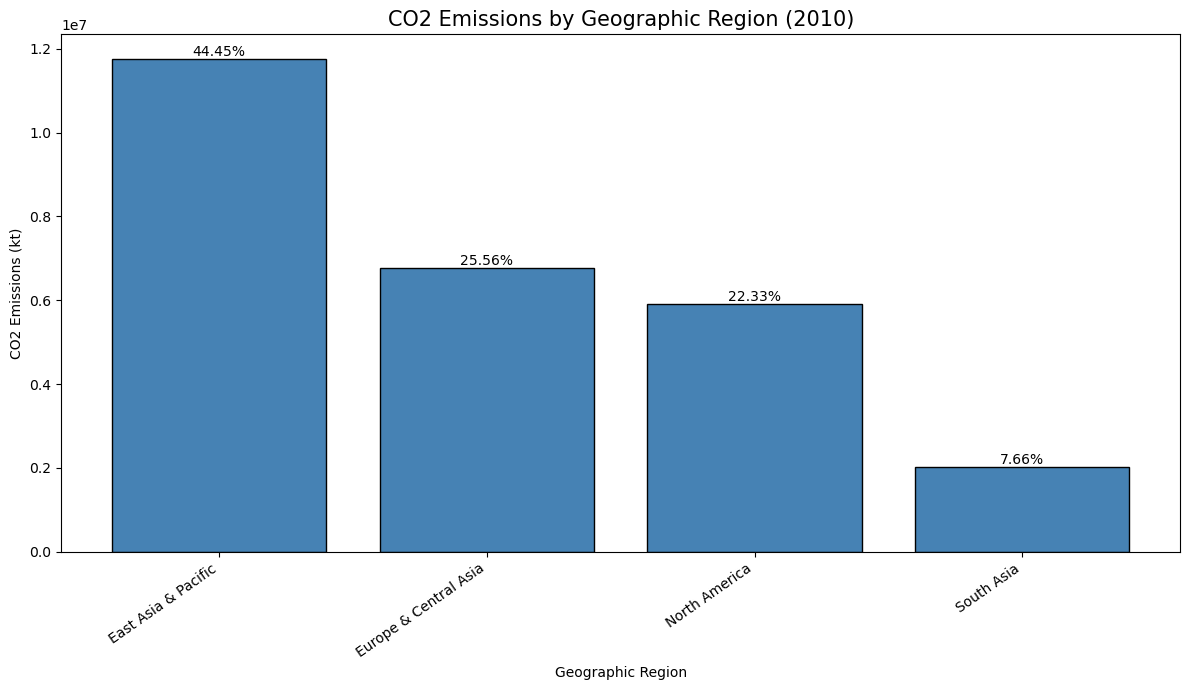

In [68]:

import pandas as pd
import matplotlib.pyplot as plt
import json
from urllib.request import urlopen

df = pd.read_csv("My Datasets/World_Bank_CO2_RawData.tsv", sep="\t")

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

with urlopen(url) as response:
    wb_data = json.loads(response.read().decode("utf-8"))

countries = wb_data[1]

country_region = {}

for country in countries:
    code = country["id"]
    region = country["region"]["value"]

    if region in [
        "East Asia & Pacific",
        "Europe & Central Asia",
        "Latin America & Caribbean",
        "Middle East & North Africa",
        "North America",
        "South Asia",
        "Sub-Saharan Africa"
    ]:
        country_region[code] = region

df["Country Code"] = df["Country Code"].astype(str).str.strip().str.upper()
df["Region"] = df["Country Code"].map(country_region)

if "Series Code" in df.columns:
    df = df[df["Series Code"].astype(str).str.strip() == "EN.ATM.CO2E.KT"].copy()

year_column = next(
    col for col in df.columns
    if str(col).strip().startswith("2010")
)

df[year_column] = pd.to_numeric(df[year_column], errors="coerce")

df_2010 = df.dropna(subset=["Region", year_column]).copy()

region_emissions = (
    df_2010.groupby("Region")[year_column]
    .sum()
    .reset_index()
)

region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

total_emissions = region_emissions["CO2 Emissions (kt)"].sum()

region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"] / total_emissions
) * 100

region_emissions = region_emissions.sort_values(
    "CO2 Emissions (kt)",
    ascending=False
).reset_index(drop=True)

region_emissions["CO2 Emissions (kt)"] = region_emissions["CO2 Emissions (kt)"].round(2)
region_emissions["Percentage (%)"] = region_emissions["Percentage (%)"].round(2)

print("CO2 EMISSIONS BY WORLD BANK GEOGRAPHIC REGION (2010)")
print(region_emissions.to_string(index=False))

print("\nTotal CO2 emissions:", round(total_emissions, 2), "kt")

plt.figure(figsize=(12, 7))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

plt.title("CO2 Emissions by Geographic Region (2010)", fontsize=15)
plt.xlabel("Geographic Region")
plt.ylabel("CO2 Emissions (kt)")
plt.xticks(rotation=35, ha="right")

for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

region_emissions.to_csv(
    "CO2_Emissions_by_Region_2010.csv",
    index=False
)




## Run 4

CO2 EMISSIONS BY GEOGRAPHICAL REGION (2010)
                     Region  CO2 Emissions (kt)  Percentage (%)
                  East Asia         10076607.97           32.25
                     Europe          6302285.88           20.17
              North America          5904973.77           18.90
                 South Asia          2197647.77            7.03
                Middle East          1828905.25            5.85
             Southeast Asia          1231275.92            3.94
              South America          1070210.28            3.43
         Sub-Saharan Africa           698394.82            2.24
Central America & Caribbean           618212.20            1.98
               North Africa           488492.07            1.56
               Central Asia           418958.42            1.34
        Australia & Oceania           407018.66            1.30

Total CO2 emissions: 31242983.01 kt
Total percentage: 99.99 %


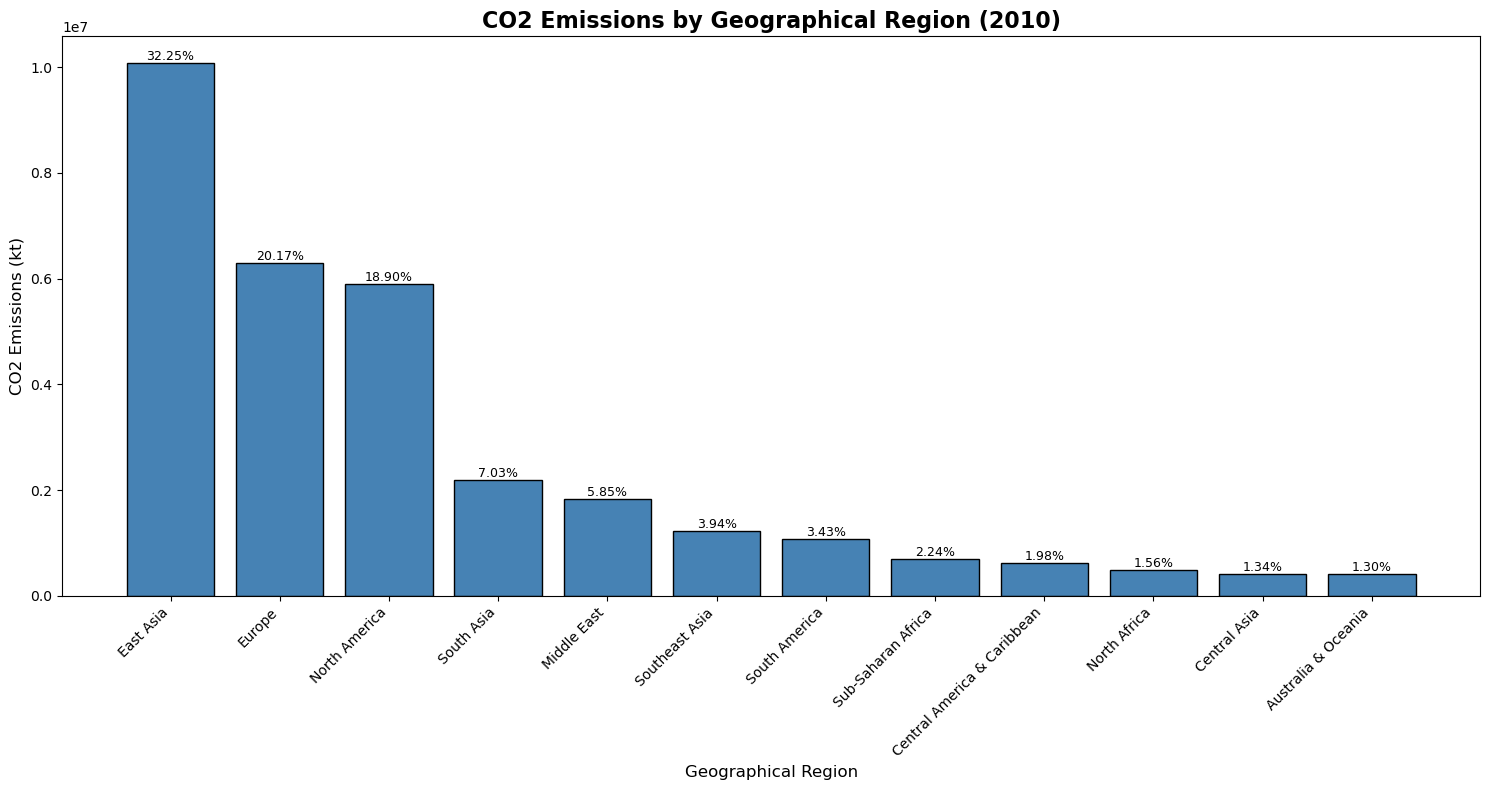


Results successfully saved!


In [70]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("My Datasets/World_Bank_CO2_RawData.tsv", sep="\t")

# 2. Create geographical region classifications using country codes

regions = {

    "East Asia": [
        "CHN", "JPN", "KOR", "PRK", "MNG", "TWN"
    ],

    "South Asia": [
        "AFG", "BGD", "BTN", "IND", "MDV",
        "NPL", "PAK", "LKA"
    ],

    "Southeast Asia": [
        "BRN", "KHM", "IDN", "LAO", "MYS",
        "MMR", "PHL", "SGP", "THA", "TLS", "VNM"
    ],

    "Central Asia": [
        "KAZ", "KGZ", "TJK", "TKM", "UZB"
    ],

    "Europe": [
        "ALB", "AND", "AUT", "BEL", "BGR", "BIH",
        "BLR", "CHE", "CZE", "DEU", "DNK", "ESP",
        "EST", "FIN", "FRA", "GBR", "GRC", "HRV",
        "HUN", "IRL", "ISL", "ITA", "LIE", "LTU",
        "LUX", "LVA", "MCO", "MDA", "MKD", "MLT",
        "MNE", "NLD", "NOR", "POL", "PRT", "ROU",
        "RUS", "SMR", "SRB", "SVK", "SVN", "SWE",
        "UKR", "VAT", "CYP", "TUR"
    ],

    "North America": [
        "CAN", "USA"
    ],

    "Central America & Caribbean": [
        "MEX", "BLZ", "CRI", "SLV", "GTM",
        "HND", "NIC", "PAN",
        "ATG", "BHS", "BRB", "CUB", "DMA",
        "DOM", "GRD", "HTI", "JAM", "KNA",
        "LCA", "VCT", "TTO"
    ],

    "South America": [
        "ARG", "BOL", "BRA", "CHL", "COL",
        "ECU", "GUY", "PRY", "PER", "SUR",
        "URY", "VEN"
    ],

    "North Africa": [
        "DZA", "EGY", "LBY", "MAR", "SDN", "TUN"
    ],

    "Sub-Saharan Africa": [
        "AGO", "BDI", "BEN", "BFA", "BWA",
        "CAF", "CIV", "CMR", "COD", "COG",
        "COM", "CPV", "DJI", "ERI", "ETH",
        "GAB", "GHA", "GIN", "GMB", "GNB",
        "GNQ", "KEN", "LBR", "LSO", "MDG",
        "MLI", "MOZ", "MRT", "MUS", "MWI",
        "NAM", "NER", "NGA", "RWA", "SEN",
        "SLE", "SOM", "SSD", "STP", "SWZ",
        "SYC", "TCD", "TGO", "TZA", "UGA",
        "ZAF", "ZMB", "ZWE"
    ],

    "Middle East": [
        "ARE", "BHR", "IRN", "IRQ", "ISR",
        "JOR", "KWT", "LBN", "OMN", "PSE",
        "QAT", "SAU", "SYR", "YEM"
    ],

    "Australia & Oceania": [
        "AUS", "NZL", "FJI", "PNG", "SLB",
        "VUT", "WSM", "TON", "KIR", "NRU",
        "PLW", "MHL", "FSM", "TUV"
    ]
}

# 3. Convert the region dictionary into a country-region dictionary

country_region = {}

for region, country_codes in regions.items():
    for code in country_codes:
        country_region[code] = region

# 4. Create the Region column

df["Country Code"] = (
    df["Country Code"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df["Region"] = df["Country Code"].map(country_region)

# 5. Select CO2 emissions indicator

if "Series Code" in df.columns:
    df = df[
        df["Series Code"].astype(str).str.strip()
        == "EN.ATM.CO2E.KT"
    ].copy()

# 6. Identify the 2010 column

year_column = next(
    col for col in df.columns
    if str(col).strip().startswith("2010")
)

# Convert emissions into numeric values

df[year_column] = pd.to_numeric(
    df[year_column],
    errors="coerce"
)

# 7. Keep only countries assigned to the 12 regions

df_2010 = df.dropna(
    subset=["Region", year_column]
).copy()

# 8. Group CO2 emissions by geographical region

region_emissions = (
    df_2010.groupby("Region")[year_column]
    .sum()
    .reindex(regions.keys(), fill_value=0)
    .reset_index()
)

region_emissions.columns = [
    "Region",
    "CO2 Emissions (kt)"
]

# 9. Calculate total emissions

total_emissions = region_emissions[
    "CO2 Emissions (kt)"
].sum()

# 10. Calculate percentage contributions

region_emissions["Percentage (%)"] = (
    region_emissions["CO2 Emissions (kt)"]
    / total_emissions
) * 100

# 11. Sort regions from highest to lowest emissions

region_emissions = region_emissions.sort_values(
    by="CO2 Emissions (kt)",
    ascending=False
).reset_index(drop=True)

# Round results

region_emissions["CO2 Emissions (kt)"] = (
    region_emissions["CO2 Emissions (kt)"].round(2)
)

region_emissions["Percentage (%)"] = (
    region_emissions["Percentage (%)"].round(2)
)

# 12. Display results table

print("CO2 EMISSIONS BY GEOGRAPHICAL REGION (2010)")
print("=" * 65)

print(region_emissions.to_string(index=False))

print("\nTotal CO2 emissions:", round(total_emissions, 2), "kt")

print(
    "Total percentage:",
    round(region_emissions["Percentage (%)"].sum(), 2),
    "%"
)

# 13. Create bar chart

plt.figure(figsize=(15, 8))

bars = plt.bar(
    region_emissions["Region"],
    region_emissions["CO2 Emissions (kt)"],
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "CO2 Emissions by Geographical Region (2010)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Geographical Region", fontsize=12)

plt.ylabel("CO2 Emissions (kt)", fontsize=12)

plt.xticks(rotation=45, ha="right")

# Add percentage labels above each bar

for bar, percentage in zip(
    bars,
    region_emissions["Percentage (%)"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.show()

# 14. Save results as a CSV file

region_emissions.to_csv(
    "CO2_Emissions_by_12_Regions_2010.csv",
    index=False
)

print("\nResults successfully saved!")


